# 1. Install the required packages

In [1]:
pip install pandas scikit-learn matplotlib vaderSentiment nltk

Note: you may need to restart the kernel to use updated packages.


# 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# 3. Load your IMDB dataset

In [5]:
df = pd.read_csv("IMDB-Dataset.csv")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### Checking Basic Structure

In [6]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nDataset information:")
df.info()

Dataset shape: (50000, 2)

Columns:
Index(['review', 'sentiment'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


# 4. Check missing values

In [7]:
print("Missing values:")
print(df.isnull().sum())


Missing values:
review       0
sentiment    0
dtype: int64


## Remove missing review/sentiment records if there are any:

In [ ]:
df = df.dropna(subset=["review", "sentiment"]).copy()

print("Shape after removing missing values:", df.shape)


# 5. Check duplicate reviews

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 418


### Removing exact duplicates

In [9]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (49582, 2)


# 6. Check class balance

In [10]:
class_counts = df["sentiment"].value_counts()

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(df["sentiment"].value_counts(normalize=True) * 100)

Class counts:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Class percentages:
sentiment
positive    50.187568
negative    49.812432
Name: proportion, dtype: float64


### Visualization

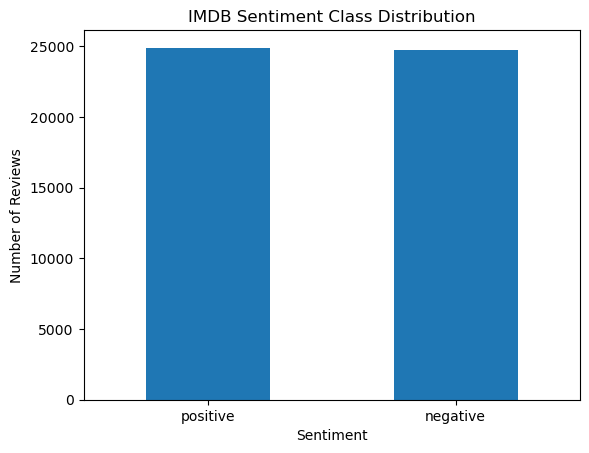

In [11]:
class_counts.plot(kind="bar")

plt.title("IMDB Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

# 7. Calculate average text length

In [12]:
df["review_length"] = df["review"].str.split().str.len()

average_length = df["review_length"].mean()

print(f"Average review length: {average_length:.2f} words")

Average review length: 231.35 words


### Inspecting per Sentiment

In [13]:
print(
    df.groupby("sentiment")["review_length"]
      .agg(["mean", "median", "min", "max"])
      .round(2)
)

             mean  median  min   max
sentiment                           
negative   229.60   174.0    4  1522
positive   233.09   172.0   10  2470


# 8. Show 10 random examples per class

In [14]:
for sentiment in ["positive", "negative"]:
    print(f"\n{'=' * 60}")
    print(f"{sentiment.upper()} EXAMPLES")
    print("=" * 60)

    examples = df[df["sentiment"] == sentiment].sample(
        n=10,
        random_state=RANDOM_SEED
    )

    for i, review in enumerate(examples["review"], start=1):
        print(f"\nExample {i}:")
        print(review[:500])
        print("-" * 60)


POSITIVE EXAMPLES

Example 1:
Not since The Simpsons made it's debut has there been a sitcom that I didn't want to turn of in a matter of 2 minutes. It has of course been said that The Simpsons killed the sitcom. Not this one though.<br /><br />The first season was so so as the teenage characters were not quite as outrageous as they later became. They even went to school sometimes. The following seasons the character where fledged out. Eric, the sarcastic twit, Donna, his levelheaded girlfriend, Kelso, the dim bulb, Hyde, th
------------------------------------------------------------

Example 2:
It's a strange thing to see a film where some scenes work rather weakly (if only in comparison to other films in its legacy), and others in a 'sub-plot' or supporting story are surprisingly provocative and strong. Sudden Impact is one of those cases, where Clint Eastwood as star/producer/director shows when he can be at his best, or at his lessor of times when dealing with a crime/mystery/det

# 9. Create the fixed train/test split

In [15]:
train_df, test_pool_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=df["sentiment"]
)

print("Training examples:", len(train_df))
print("Test-pool examples:", len(test_pool_df))

Training examples: 39665
Test-pool examples: 9917


# 10. Create the fixed 300-review test subset

In [16]:
test_300, _ = train_test_split(
    test_pool_df,
    train_size=300,
    random_state=RANDOM_SEED,
    stratify=test_pool_df["sentiment"]
)

test_300 = test_300.reset_index(drop=True)
train_df = train_df.reset_index(drop=True)

print("Final training set:", len(train_df))
print("Fixed test subset:", len(test_300))

Final training set: 39665
Fixed test subset: 300


### Checking the test balance

In [17]:
print(test_300["sentiment"].value_counts())

print("\nPercentages:")
print(test_300["sentiment"].value_counts(normalize=True) * 100)

sentiment
positive    151
negative    149
Name: count, dtype: int64

Percentages:
sentiment
positive    50.333333
negative    49.666667
Name: proportion, dtype: float64


# 11. Freezing and saving the datasets

In [18]:
train_df.to_csv("train.csv", index=False)
test_300.to_csv("test_300.csv", index=False)

print("Datasets saved successfully.")

Datasets saved successfully.


# 12. Final verification

In [20]:
print("DATA PREPARATION SUMMARY")
print("=" * 50)

print(f"Total cleaned reviews: {len(df):,}")
print(f"Training reviews: {len(train_df):,}")
print(f"Fixed test reviews: {len(test_300):,}")
print(f"Average review length: {average_length:.2f} words")

print("\nTraining class distribution:")
print(train_df["sentiment"].value_counts())

print("\nTest class distribution:")
print(test_300["sentiment"].value_counts())

DATA PREPARATION SUMMARY
Total cleaned reviews: 49,582
Training reviews: 39,665
Fixed test reviews: 300
Average review length: 231.35 words

Training class distribution:
sentiment
positive    19907
negative    19758
Name: count, dtype: int64

Test class distribution:
sentiment
positive    151
negative    149
Name: count, dtype: int64
